# Türkiye'de Tahıl Verimi: Veri Analizi

**Çalışma sorusu:** Türkiye'de hektar başına tahıl verimi 1995–2024 arasında nasıl değişti ve yıllık artış/düşüşler hangi yıllarda belirginleşti?

Kaynak: Dünya Bankası, *Cereal yield (kg per hectare)*, gösterge kodu `AG.YLD.CREL.KG`.

In [10]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Notebook proje kökünden çalıştırılacak şekilde dosya yolunu bulur.
possible_paths = [
    Path('../data/processed/tahil_verimi_1995_2024.csv'),
    Path('data/processed/tahil_verimi_1995_2024.csv'),
    Path('../site/data/tahil_verimi_1995_2024.csv'),
    Path('processed/tahil_verimi_1995_2024.csv'),
]
csv_path = next((p for p in possible_paths if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError('İşlenmiş CSV bulunamadı. Notebook proje kökünden veya notebooks klasöründen çalıştırılmalı.')
df = pd.read_csv(csv_path)
df.head()

,Country Name,Yıl,Tahıl Verimi (kg/ha),Yıllık Değişim (%)
0,Turkiye,1995,2057.3,NaN
1,Turkiye,1996,2112.3,2.673407
2,Turkiye,1997,2151.3,1.846329
3,Turkiye,1998,2387.5,10.979408
4,Turkiye,1999,2099.8,-12.050262


In [11]:
print('Boyut:', df.shape)
print('\nVeri tipleri:')
print(df.dtypes)
print('\nEksik değer sayıları:')
print(df.isna().sum())
print('\nÖzet istatistikler:')
display(df.describe(include='all'))

Boyut: (30, 4)

Veri tipleri:
Country Name             object
Yıl                       int64
Tahıl Verimi (kg/ha)    float64
Yıllık Değişim (%)      float64
dtype: object

Eksik değer sayıları:
Country Name            0
Yıl                     0
Tahıl Verimi (kg/ha)    0
Yıllık Değişim (%)      1
dtype: int64

Özet istatistikler:


,Country Name,Yıl,Tahıl Verimi (kg/ha),Yıllık Değişim (%)
count,30,30.000000,30.000000,29.000000
unique,1,NaN,NaN,NaN
top,Turkiye,NaN,NaN,NaN
freq,30,NaN,NaN,NaN
mean,NaN,2009.500000,2769.736667,2.122873
std,NaN,8.803408,475.208345,8.494437
min,NaN,1995.000000,2057.300000,-13.043078
25%,NaN,2002.250000,2374.825000,-2.927559
50%,NaN,2009.500000,2766.700000,2.924299
75%,NaN,2016.750000,3191.575000,7.928803


In [12]:
df['Yıl'] = pd.to_numeric(df['Yıl'], errors='coerce')
df['Tahıl Verimi (kg/ha)'] = pd.to_numeric(df['Tahıl Verimi (kg/ha)'], errors='coerce')
df = df.dropna(subset=['Yıl', 'Tahıl Verimi (kg/ha)']).sort_values('Yıl').reset_index(drop=True)
df['Yıllık Değişim (%)'] = df['Tahıl Verimi (kg/ha)'].pct_change() * 100
print(f"Analiz aralığı: {int(df['Yıl'].min())}–{int(df['Yıl'].max())}")
print('Gözlem sayısı:', len(df))
df.head()

Analiz aralığı: 1995–2024
Gözlem sayısı: 30


,Country Name,Yıl,Tahıl Verimi (kg/ha),Yıllık Değişim (%)
0,Turkiye,1995,2057.3,NaN
1,Turkiye,1996,2112.3,2.673407
2,Turkiye,1997,2151.3,1.846329
3,Turkiye,1998,2387.5,10.979408
4,Turkiye,1999,2099.8,-12.050262


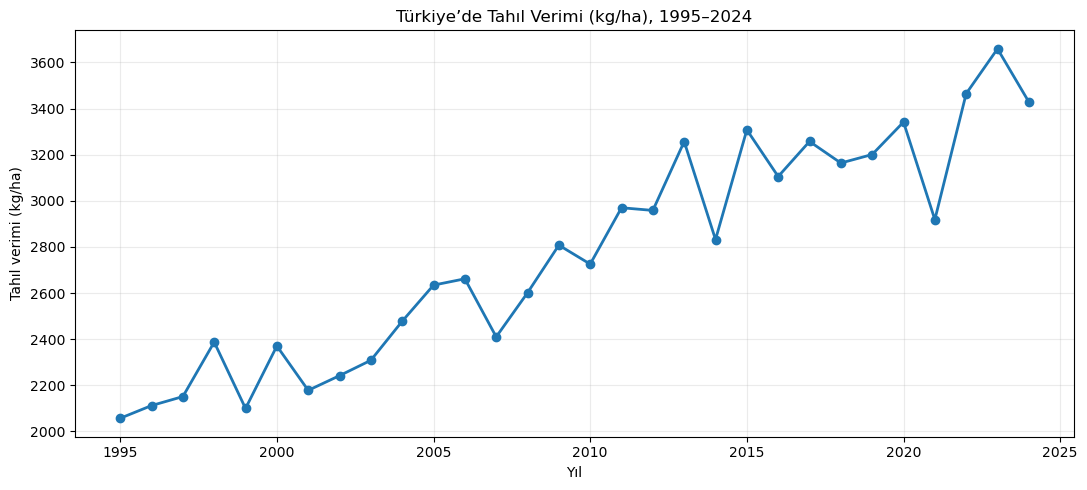

In [13]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(df['Yıl'], df['Tahıl Verimi (kg/ha)'], marker='o', linewidth=2)
ax.set_title('Türkiye’de Tahıl Verimi (kg/ha), 1995–2024')
ax.set_xlabel('Yıl')
ax.set_ylabel('Tahıl verimi (kg/ha)')
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

In [14]:
min_row = df.loc[df['Tahıl Verimi (kg/ha)'].idxmin()]
max_row = df.loc[df['Tahıl Verimi (kg/ha)'].idxmax()]
change_df = df.dropna(subset=['Yıllık Değişim (%)'])
max_rise = change_df.loc[change_df['Yıllık Değişim (%)'].idxmax()]
max_drop = change_df.loc[change_df['Yıllık Değişim (%)'].idxmin()]
summary = pd.DataFrame([
    {'Bulgu':'En düşük verim', 'Yıl':int(min_row['Yıl']), 'Değer':min_row['Tahıl Verimi (kg/ha)'], 'Birim':'kg/ha'},
    {'Bulgu':'En yüksek verim', 'Yıl':int(max_row['Yıl']), 'Değer':max_row['Tahıl Verimi (kg/ha)'], 'Birim':'kg/ha'},
    {'Bulgu':'En büyük yıllık artış', 'Yıl':int(max_rise['Yıl']), 'Değer':max_rise['Yıllık Değişim (%)'], 'Birim':'%'},
    {'Bulgu':'En büyük yıllık düşüş', 'Yıl':int(max_drop['Yıl']), 'Değer':max_drop['Yıllık Değişim (%)'], 'Birim':'%'}
])
display(summary)
print('Not: Yıllık değişim, önceki yılın verimine göre yüzde değişimdir; neden-sonuç ilişkisi göstermez.')

,Bulgu,Yıl,Değer,Birim
0,En düşük verim,1995,2057.300000,kg/ha
1,En yüksek verim,2023,3659.100000,kg/ha
2,En büyük yıllık artış,2022,18.715093,%
3,En büyük yıllık düşüş,2014,-13.043078,%


Not: Yıllık değişim, önceki yılın verimine göre yüzde değişimdir; neden-sonuç ilişkisi göstermez.


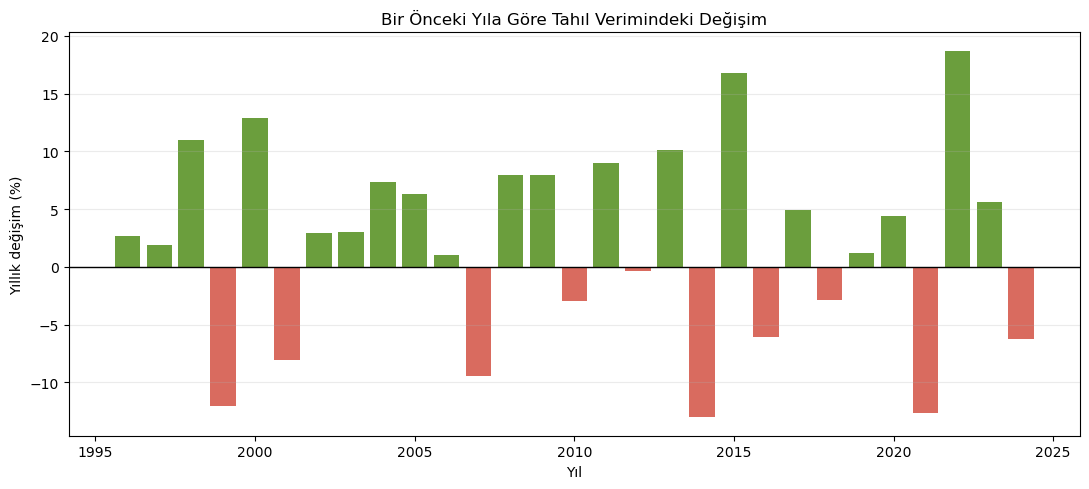

In [15]:
fig, ax = plt.subplots(figsize=(11, 5))
colors = ['#6b9e3d' if x >= 0 else '#d96b5f' for x in change_df['Yıllık Değişim (%)']]
ax.bar(change_df['Yıl'], change_df['Yıllık Değişim (%)'], color=colors)
ax.axhline(0, color='black', linewidth=1)
ax.set_title('Bir Önceki Yıla Göre Tahıl Verimindeki Değişim')
ax.set_xlabel('Yıl')
ax.set_ylabel('Yıllık değişim (%)')
ax.grid(axis='y', alpha=.25)
plt.tight_layout()
plt.show()

## Yöntem ve sınırlılıklar

- Kaynak gösterge: Dünya Bankası `AG.YLD.CREL.KG` — cereal yield (kg/ha).
- İşlem: yıl ve verim sütunları sayısala çevrildi; bu alanlarda eksik olmayan gözlemler seçildi; yıllara göre sıralandı; yıllık yüzde değişim `pct_change()` ile hesaplandı.
- Tahıl verimi hektar başına verimdir; toplam üretim miktarı değildir.
- Yağış, sıcaklık, ekili alan veya tarım uygulamalarına ilişkin ek değişkenler analiz edilmediği için düşüş ve artışların nedenleri hakkında kesin iddia kurulamaz.
- Bu notebook, scrollytelling sitesinde kullanılan özet CSV'yi üretmek ve bulguları yeniden hesaplamak için hazırlanmıştır.